In [1]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
!pip install -q git+https://github.com/tensorflow/examples.git

  Preparing metadata (setup.py) ... done


In [3]:
import tensorflow as tf
import os
import matplotlib.pyplot as plt

dataset_url = "http://efrosgans.eecs.berkeley.edu/pix2pix/datasets/facades.tar.gz"

path_to_zip = tf.keras.utils.get_file(
    "facades.tar.gz",
    origin=dataset_url,
    extract=True
)

PATH = os.path.join(os.path.dirname(path_to_zip), "facades")

train_files = tf.io.gfile.glob(os.path.join(PATH, "train", "*.jpg"))
test_files = tf.io.gfile.glob(os.path.join(PATH, "test", "*.jpg"))

print("Dataset downloaded successfully!")
print("Training images:", len(train_files))
print("Testing images:", len(test_files))

30168306/30168306 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
Dataset downloaded successfully!
Training images: 0
Testing images: 0


In [5]:
import os
import glob

dataset_folder = os.path.dirname(path_to_zip)

print("Dataset folder:")
print(dataset_folder)

all_images = glob.glob(
    os.path.join(dataset_folder, "**", "*"),
    recursive=True
)

all_images = [
    file for file in all_images
    if file.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Total image files found:", len(all_images))
print("First few files:")

for file in all_images[:5]:
    print(file)

Dataset folder:
/root/.keras/datasets
Total image files found: 606
First few files:
/root/.keras/datasets/facades_extracted/facades/val/21.jpg
/root/.keras/datasets/facades_extracted/facades/val/44.jpg
/root/.keras/datasets/facades_extracted/facades/val/18.jpg
/root/.keras/datasets/facades_extracted/facades/val/97.jpg
/root/.keras/datasets/facades_extracted/facades/val/62.jpg


In [6]:
train_files = [
    file for file in all_images
    if "/train/" in file.replace("\\", "/")
]

test_files = [
    file for file in all_images
    if "/test/" in file.replace("\\", "/")
]

print("Training images:", len(train_files))
print("Testing images:", len(test_files))

Training images: 400
Testing images: 106


Image shape: (256, 512, 3)


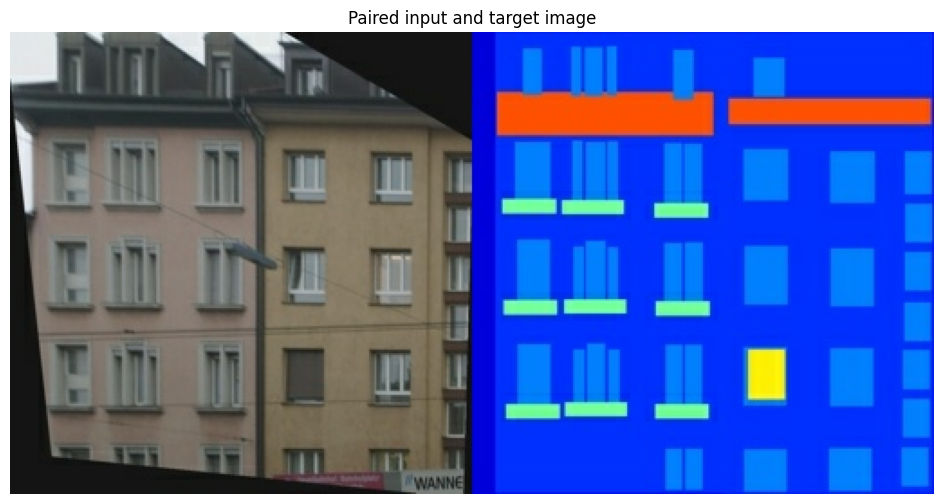

In [7]:
image_data = tf.io.read_file(train_files[0])
image = tf.io.decode_image(image_data, channels=3)

print("Image shape:", image.shape)

plt.figure(figsize=(12, 6))
plt.imshow(image)
plt.axis("off")
plt.title("Paired input and target image")
plt.show()

In [8]:
IMG_WIDTH = 256
IMG_HEIGHT = 256

def load_image(image_file):
    image_data = tf.io.read_file(image_file)
    image = tf.io.decode_jpeg(image_data)

    # The image contains two 256x256 images side by side
    width = tf.shape(image)[1]
    half_width = width // 2

    # In this dataset:
    # left side = real image
    # right side = building label
    real_image = image[:, :half_width, :]
    input_image = image[:, half_width:, :]

    return input_image, real_image


def resize_images(input_image, real_image, height, width):
    input_image = tf.image.resize(
        input_image,
        [height, width],
        method=tf.image.ResizeMethod.NEAREST_NEIGHBOR
    )

    real_image = tf.image.resize(
        real_image,
        [height, width],
        method=tf.image.ResizeMethod.NEAREST_NEIGHBOR
    )

    return input_image, real_image


def random_crop(input_image, real_image):
    combined_image = tf.concat([input_image, real_image], axis=0)

    cropped_image = tf.image.random_crop(
        combined_image,
        size=[IMG_HEIGHT * 2, IMG_WIDTH, 3]
    )

    input_image = cropped_image[:IMG_HEIGHT, :, :]
    real_image = cropped_image[IMG_HEIGHT:, :, :]

    return input_image, real_image


def normalize(image):
    image = tf.cast(image, tf.float32)
    return (image / 127.5) - 1


def load_image_train(image_file):
    input_image, real_image = load_image(image_file)

    input_image, real_image = resize_images(
        input_image,
        real_image,
        286,
        286
    )

    input_image, real_image = random_crop(
        input_image,
        real_image
    )

    # Randomly flip images for data augmentation
    if tf.random.uniform(()) > 0.5:
        input_image = tf.image.flip_left_right(input_image)
        real_image = tf.image.flip_left_right(real_image)

    return normalize(input_image), normalize(real_image)


def load_image_test(image_file):
    input_image, real_image = load_image(image_file)

    input_image, real_image = resize_images(
        input_image,
        real_image,
        IMG_HEIGHT,
        IMG_WIDTH
    )

    return normalize(input_image), normalize(real_image)


print("Image preprocessing functions created successfully!")

Image preprocessing functions created successfully!


In [9]:
BUFFER_SIZE = 400
BATCH_SIZE = 1

train_dataset = (
    tf.data.Dataset
    .from_tensor_slices(train_files)
    .map(load_image_train, num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(BUFFER_SIZE)
    .batch(BATCH_SIZE)
)

test_dataset = (
    tf.data.Dataset
    .from_tensor_slices(test_files)
    .map(load_image_test, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
)

print("Training and testing datasets prepared!")

Training and testing datasets prepared!


In [10]:
from tensorflow_examples.models.pix2pix import pix2pix

OUTPUT_CHANNELS = 3

# U-Net generator
generator = pix2pix.unet_generator(
    OUTPUT_CHANNELS,
    norm_type="instancenorm"
)

# PatchGAN discriminator
discriminator = pix2pix.discriminator(
    norm_type="instancenorm",
    target=True
)

print("Generator created successfully!")
print("Discriminator created successfully!")

Generator created successfully!
Discriminator created successfully!


In [11]:
sample_input, sample_target = next(iter(train_dataset))

generated_image = generator(sample_input, training=False)
discriminator_result = discriminator(
    [sample_input, generated_image],
    training=False
)

print("Input image shape:", sample_input.shape)
print("Generated image shape:", generated_image.shape)
print("Discriminator output shape:", discriminator_result.shape)

Input image shape: (1, 256, 256, 3)
Generated image shape: (1, 256, 256, 3)
Discriminator output shape: (1, 30, 30, 1)


In [12]:
loss_object = tf.keras.losses.BinaryCrossentropy(
    from_logits=True
)

LAMBDA = 100


def discriminator_loss(real_output, generated_output):
    real_loss = loss_object(
        tf.ones_like(real_output),
        real_output
    )

    generated_loss = loss_object(
        tf.zeros_like(generated_output),
        generated_output
    )

    total_loss = real_loss + generated_loss
    return total_loss


def generator_loss(generated_output, generated_image, target_image):
    gan_loss = loss_object(
        tf.ones_like(generated_output),
        generated_output
    )

    # L1 loss helps preserve the structure of the target image
    l1_loss = tf.reduce_mean(
        tf.abs(target_image - generated_image)
    )

    total_loss = gan_loss + (LAMBDA * l1_loss)

    return total_loss, gan_loss, l1_loss


generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=2e-4,
    beta_1=0.5
)

discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=2e-4,
    beta_1=0.5
)

print("Loss functions and optimizers created successfully!")

Loss functions and optimizers created successfully!


In [13]:
@tf.function
def train_step(input_image, target_image):
    with tf.GradientTape() as generator_tape, \
         tf.GradientTape() as discriminator_tape:

        generated_image = generator(
            input_image,
            training=True
        )

        real_output = discriminator(
            [input_image, target_image],
            training=True
        )

        generated_output = discriminator(
            [input_image, generated_image],
            training=True
        )

        generator_total_loss, generator_gan_loss, generator_l1_loss = (
            generator_loss(
                generated_output,
                generated_image,
                target_image
            )
        )

        discriminator_total_loss = discriminator_loss(
            real_output,
            generated_output
        )

    generator_gradients = generator_tape.gradient(
        generator_total_loss,
        generator.trainable_variables
    )

    discriminator_gradients = discriminator_tape.gradient(
        discriminator_total_loss,
        discriminator.trainable_variables
    )

    generator_optimizer.apply_gradients(
        zip(generator_gradients, generator.trainable_variables)
    )

    discriminator_optimizer.apply_gradients(
        zip(discriminator_gradients, discriminator.trainable_variables)
    )

    return generator_total_loss, discriminator_total_loss

In [14]:
import time

EPOCHS = 5

for epoch in range(EPOCHS):
    start_time = time.time()

    print(f"\nStarting epoch {epoch + 1}/{EPOCHS}")

    for step, (input_image, target_image) in enumerate(train_dataset):
        generator_loss_value, discriminator_loss_value = train_step(
            input_image,
            target_image
        )

        if (step + 1) % 50 == 0:
            print(
                f"Step {step + 1} | "
                f"Generator loss: {generator_loss_value:.4f} | "
                f"Discriminator loss: {discriminator_loss_value:.4f}"
            )

    elapsed_time = time.time() - start_time

    print(
        f"Epoch {epoch + 1} completed in "
        f"{elapsed_time / 60:.2f} minutes"
    )

print("\nTraining completed successfully!")


Starting epoch 1/5
Step 50 | Generator loss: 29.1437 | Discriminator loss: 1.6640
Step 100 | Generator loss: 36.3218 | Discriminator loss: 0.7891
Step 150 | Generator loss: 53.4653 | Discriminator loss: 0.4584
Step 200 | Generator loss: 49.6545 | Discriminator loss: 0.8393
Step 250 | Generator loss: 36.3085 | Discriminator loss: 0.1795
Step 300 | Generator loss: 58.5032 | Discriminator loss: 0.5677
Step 350 | Generator loss: 36.3489 | Discriminator loss: 0.5288
Step 400 | Generator loss: 33.8743 | Discriminator loss: 0.9190
Epoch 1 completed in 1.37 minutes

Starting epoch 2/5
Step 50 | Generator loss: 40.4278 | Discriminator loss: 0.1549
Step 100 | Generator loss: 32.1851 | Discriminator loss: 2.4223
Step 150 | Generator loss: 38.8584 | Discriminator loss: 0.1976
Step 200 | Generator loss: 32.1874 | Discriminator loss: 0.5186
Step 250 | Generator loss: 46.4308 | Discriminator loss: 0.2545
Step 300 | Generator loss: 30.0657 | Discriminator loss: 0.2979
Step 350 | Generator loss: 32.78

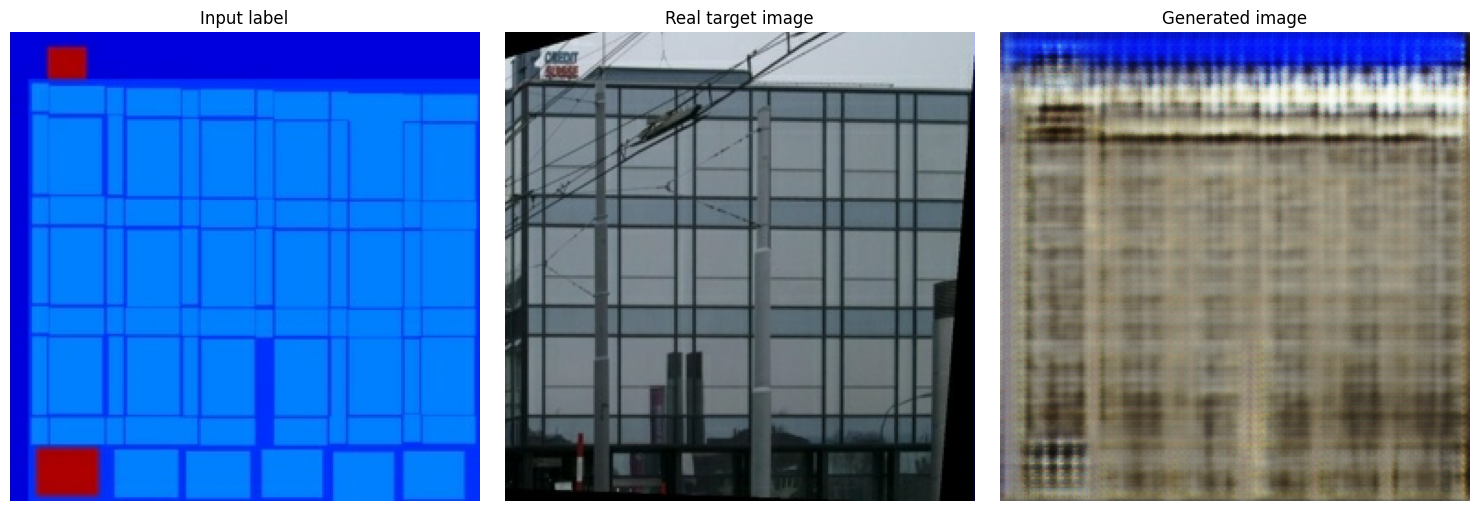

Generated image saved successfully!


In [15]:
import matplotlib.pyplot as plt

def generate_and_display(model, input_image, target_image):
    prediction = model(input_image, training=False)

    display_images = [
        input_image[0],
        target_image[0],
        prediction[0]
    ]

    titles = [
        "Input label",
        "Real target image",
        "Generated image"
    ]

    plt.figure(figsize=(15, 5))

    for index in range(3):
        plt.subplot(1, 3, index + 1)

        # Convert pixel values from [-1, 1] to [0, 1]
        image = (display_images[index] + 1) / 2

        plt.imshow(image)
        plt.title(titles[index])
        plt.axis("off")

    plt.tight_layout()
    plt.savefig("pix2pix_result.png")
    plt.show()

    # Save only the generated image
    generated_image = (prediction[0] + 1) / 2
    tf.keras.utils.save_img(
        "pix2pix_generated_image.png",
        generated_image
    )

    print("Generated image saved successfully!")


example_input, example_target = next(iter(test_dataset))

generate_and_display(
    generator,
    example_input,
    example_target
)

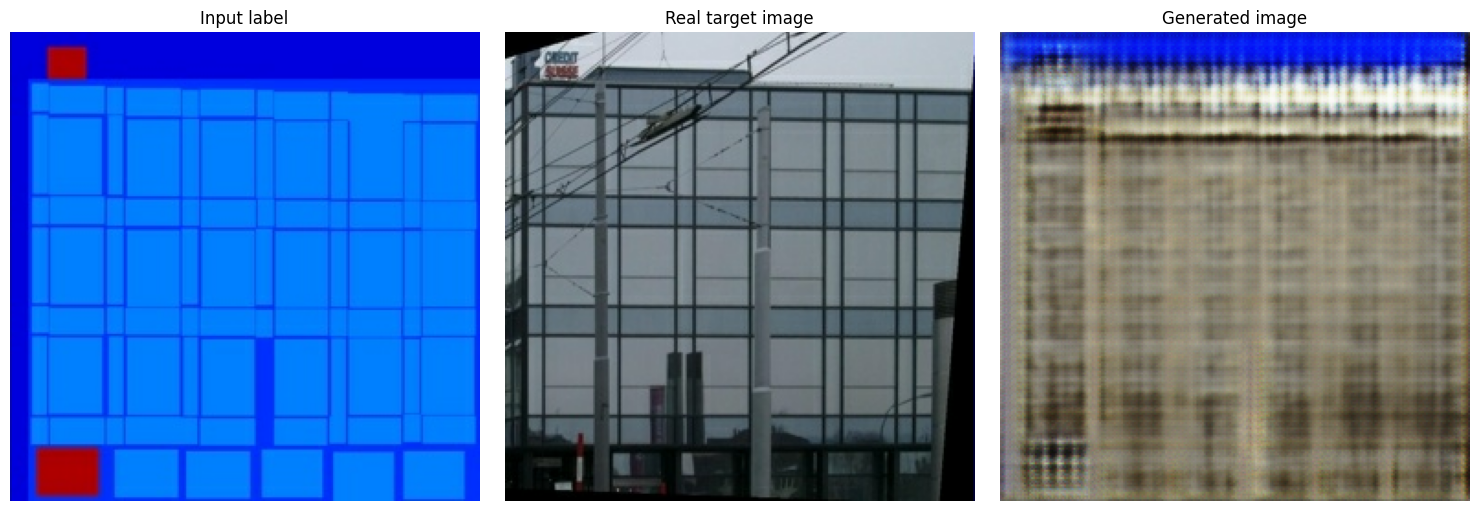

Generated image saved successfully!


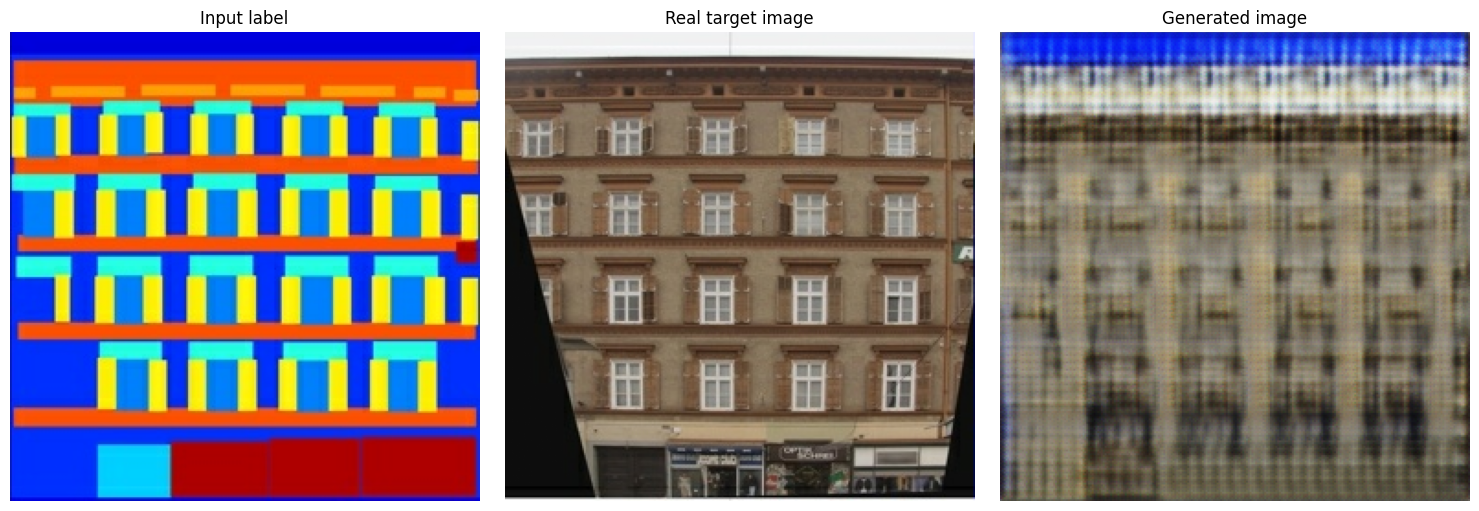

Generated image saved successfully!


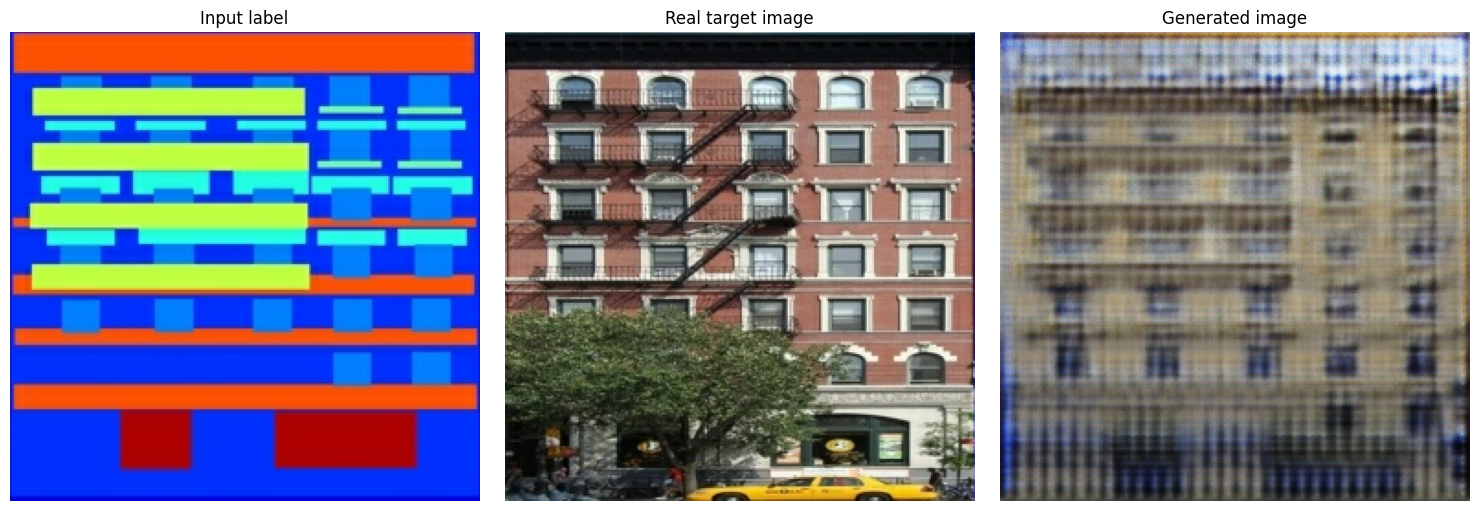

Generated image saved successfully!


In [16]:
for example_input, example_target in test_dataset.take(3):
    generate_and_display(
        generator,
        example_input,
        example_target
    )

# Image-to-Image Translation with pix2pix cGAN

## 1. Objective

The objective of this project is to implement an image-to-image translation model using a conditional generative adversarial network called pix2pix.

The model learns to convert a building label or sketch into a realistic building image.

## 2. Dataset

The Facades dataset was used. It contains paired images:

- Input: building label or sketch
- Target: real building photograph

Each paired image contains the input and target images side by side.

## 3. Model Architecture

The pix2pix model contains two neural networks:

### Generator

The generator uses a U-Net architecture. It receives a building label as input and produces a realistic building image.

### Discriminator

The discriminator uses a PatchGAN architecture. It examines small patches of the input and target images and predicts whether the generated image looks real.

## 4. Training Method

The model was trained using:

- Epochs: 5
- Batch size: 1
- Optimizer: Adam
- Learning rate: 0.0002
- Beta 1: 0.5
- L1 loss weight: 100
- Hardware: Google Colab T4 GPU

The generator loss included adversarial loss and L1 reconstruction loss. The L1 loss helped the generated image preserve the structure of the target image.

## 5. Results

The trained model generated images from building labels. The results were displayed in three parts:

1. Input building label
2. Real target photograph
3. Generated building image

The generated images showed that the pix2pix model learned some visual patterns from the training dataset.

## 6. Limitations

The model was trained for only five epochs, so the generated images may not be highly realistic. Some images may contain blurry areas or incorrect details.

Better results could be achieved using more training epochs, a larger dataset, longer training time, and more powerful hardware.

## 7. Conclusion

This project successfully implemented an image-to-image translation model using a conditional GAN called pix2pix.

The experiment demonstrated how a generator can learn to create realistic images from structured input images, while a discriminator evaluates whether the generated images look realistic.